# Transformación evolutiva de atributos v2: aumentar, ponderar y reducir

**Práctica final — IA con inspiración biológica** · Máster en Ciencia y Tecnología, UC3M · Andrea López Salazar

Aprendemos con **CMA-ES**, viendo solo el entrenamiento, una transformación $X \to X'$ con **menos atributos que $X$** ($\dim X'<n$). La versión 2 cambia dos cosas respecto a la primera:

1. **Aumentar y luego reducir.** Se construyen $2n$ candidatos (los $n$ atributos con su forma Yeo-Johnson y sus $n$ componentes principales), cada uno con su propio peso ("pesos dobles"), y la evolución se queda con los de peso $\ge \tau$, como mucho $n-1$.
2. **Fitness de varios modelos.** La búsqueda minimiza la **media del MAE normalizado de KNN, regresión lineal y un árbol**, no solo el de KNN, para que la representación sirva a modelos de familias distintas.

**Resultados** (12 datasets × 5 particiones de confirmación, las mismas de la v1): $X'$ usa el **83 %** de los atributos y siempre menos de $n$, con componentes en el 93 % de las particiones. El error baja en **regresión lineal −14,6 %** (11/12 datasets, significativo; la v1 se quedaba en −4,4 %) y en **KNN −21,2 %** (9/12; la v1 llegaba a −24,3 %). En árbol y Random Forest **no cambia en media**. En media de los cuatro modelos, la v2 mejora un −9,5 % frente al −7,6 % de la v1, y es la **mejor transformación de las que no aumentan la dimensión**. La **parada por sobreajuste** con datos apartados se probó y se descartó: ahorra tiempo, pero empeora el error.

## 0. Cómo ejecutarlo

**Instalación** (una vez, desde la carpeta `PTCA-FINAL/`):

```bash
python -m venv .venv && source .venv/bin/activate      # en Windows: .venv\Scripts\activate
pip install -r requirements.txt
jupyter lab v2/notebook_v2.ipynb
```

- La **primera vez** hace falta internet: diez de los doce datasets se descargan de OpenML (se guardan en `~/scikit_learn_data`).
- Por defecto el notebook **no repite los experimentos**: lee los CSV guardados y rehace el análisis, las figuras y las cifras de los documentos en unos segundos. Para repetir uno, pon su entrada de `RECALCULAR` a `True` (el CSV anterior se guarda como `.bak`).
- `N_JOBS` = procesos en paralelo (por defecto, todos los núcleos). Tiempos con 20 núcleos; con $k$ núcleos, multiplícalos por $\approx 20/k$.

| Experimento | Script | Qué produce | Tiempo (20 núcleos) |
|---|---|---|---|
| `final` | `final/experimento_final.py` | referencias (original, estándar) y $P$ sin reducir ($2n$) | ≈ 20 min |
| `reduccion` | `reduccion/experimento_reduccion.py` | $P$ v1 (fitness KNN), para comparar | ≈ 25 min |
| `cribado_v2` | `v2/cribado_v2.py` | diseño de v2: variantes en semillas de exploración 0–1 | ≈ 15 min |
| `confirmacion_v2` | `v2/experimento_v2.py` | **$P$ v2** en las particiones de confirmación | ≈ 20 min |
| `comparativa` | `final/experimento_comparativa.py` | 8 transformaciones alternativas (necesita `final`) | ≈ 8 min |
| `busqueda_*` | `final/experimento_busqueda.py <bloque>` | ablación de la búsqueda de $(\lambda,w)$ | 10–25 min cada uno |
| `parada` | `final/experimento_parada.py` | comportamiento de CMA-ES | ≈ 5 min |

In [1]:
import os, sys, shutil, subprocess, inspect, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.precision", 3)

# ---------------------------------------------------------------- configuración
N_JOBS = os.cpu_count()
RECALCULAR = {"final": False, "reduccion": False, "cribado_v2": False, "confirmacion_v2": False, "comparativa": False,
              "busqueda_controles": False, "busqueda_rango": False, "busqueda_algoritmos": False,
              "busqueda_inicio": False, "parada": False}
PRESUPUESTO_DEMO = 300              # evaluaciones de CMA-ES en la demostración (el método usa 1000)
COMPILAR_LATEX = False              # True = recompilar memoria, paper y póster de v2 (requiere LaTeX)

V2 = os.path.abspath(".")
RAIZ = os.path.dirname(V2)
FINAL, REDUC = os.path.join(RAIZ, "final"), os.path.join(RAIZ, "reduccion")
sys.path[:0] = [V2, FINAL, REDUC]
import metodo_v2 as v2, metodo, analisis as A, analisis_v2 as A2
print("Python", sys.version.split()[0], "·", N_JOBS, "procesos")

Python 3.14.10 · 22 procesos


## 1. El problema

El enunciado pide un programa $P$ que, a partir **solo** de $(X_t, y_t)$:

- haga **síntesis** de atributos y **reducción de la dimensionalidad** ($\dim X' < n$), con un **criterio de eliminación que dependa del algoritmo evolutivo**;
- consiga que un modelo **arbitrario** $M$ entrenado con $X'_t$ tenga menor MAE en validación que con $X_t$ ($e'<e$).

Cada familia de modelos es sensible a cosas distintas: KNN a la geometría (escalas, atributos ruidosos), la regresión lineal a la forma de cada atributo y los árboles solo a las **direcciones** por las que pueden cortar (son invariantes a cualquier cambio monótono por atributo).

**Qué falló en la v1.** La v1 (fitness solo de KNN) cumplía $\dim X'<n$ y mejoraba mucho a KNN, pero no a los árboles: como un árbol no cambia con la forma ni con los pesos, solo le ayudan las componentes (cortes oblicuos), y el fitness de KNN no tenía motivo para guardarles sitio en el presupuesto de $n-1$ atributos.

## 2. El método (P v2)

![Esquema de P v2](figuras/esquema_v2.png)

**Genoma** $\theta = (\lambda_1..\lambda_n,\; v_1..v_{2n},\; \tau)$, con $3n+1$ números reales:

| Gen | Rango | Papel |
|---|---|---|
| $\lambda_j$ | $[-2, 2]$ | **forma**: exponente de Yeo-Johnson del atributo $j$ |
| $v_1..v_n$ | $[0, 3]$ | **peso** de cada atributo original (con su forma, estandarizado) |
| $v_{n+1}..v_{2n}$ | $[0, 3]$ | **peso** de cada componente principal (estandarizada) |
| $\tau$ | $[0, 3]$ | **umbral de eliminación** |

**Decodificación** (cualquier $\theta$ da un $X'$ válido):

1. $\tilde x_j = (\psi(x_j;\lambda_j) - \mu_j)/\sigma_j$ (forma + estandarizar, con $\mu,\sigma$ del entrenamiento).
2. **Aumentar**: $c = [\,\tilde x_1..\tilde x_n \mid p_1..p_n\,]$, con $p$ las componentes principales de $\tilde x$ estandarizadas. Se calculan **antes** de ponderar, así no hay dependencia circular y es barato.
3. **Ponderar**: $v_k\,c_k$.
4. **Reducir**: se conservan los $k$ con $v_k \ge \tau$; si son $n$ o más, los $n-1$ de mayor peso; si no queda ninguno, el de mayor peso. $\dim X' \le n-1$ siempre.

**Fitness**: media de los MAE de validación cruzada (5 pliegues) de **KNN ($k=5$), regresión lineal y un árbol de decisión**, cada uno dividido por el MAE de predecir la mediana, en una submuestra de hasta 2000 filas. El árbol hace de sustituto barato de Random Forest, que solo se mide al final. **Búsqueda**: CMA-ES, 1000 evaluaciones, inicio en $\theta_0$ = estandarizar sin componentes ($\lambda=1$, $v_{orig}=1$, $v_{comp}=0$, $\tau=0{,}5$).

**Por qué el criterio de eliminación es evolutivo**: CMA-ES decide qué candidatos sobreviven (originales o componentes, por sus pesos) y cuántos (por $\tau$). La restricción $\dim X'<n$ está en la decodificación.

In [2]:
print(inspect.getsource(v2.TransformacionV2))
print(inspect.getsource(v2.hacer_fitness))

class TransformacionV2:
    def __init__(self, theta, n):
        self.theta, self.n = np.asarray(theta, float), n

    def fit(self, Xt):
        n, th = self.n, self.theta
        self.lam, self.v, self.tau = th[:n], th[n:3 * n], float(th[3 * n])
        T = metodo.yeo_johnson(Xt, self.lam)
        self.mu, self.sd = T.mean(0), T.std(0)
        self.sd[self.sd == 0] = 1.0
        C = (T - self.mu) / self.sd
        self.V = np.linalg.svd(C, full_matrices=False)[2].T          # componentes del espacio con forma
        P = C @ self.V
        self.psd = P.std(0)
        self.psd[self.psd < 1e-12] = 1.0
        S = np.where(self.v >= self.tau)[0]
        if len(S) >= n:                                              # restricción: como mucho n − 1
            S = np.sort(S[np.argsort(-self.v[S])[:n - 1]])
        if len(S) == 0:
            S = np.array([np.argmax(self.v)])
        self.S = S
        return self

    def candidatos(self, X):
        C = (metodo.yeo_johnson(X, self.lam) - 

## 3. Demostración en vivo

$P$ v2 sobre una partición de los dos datasets de la práctica con `PRESUPUESTO_DEMO` evaluaciones. $P$ solo ve el entrenamiento.

In [3]:
from sklearn.model_selection import train_test_split
from experimento_final import modelos

SEMILLA = 40
demo, filas = {}, []
for nombre in ["california", "diabetes"]:
    X, y = metodo.cargar(nombre)
    Xt, Xv, yt, yv = train_test_split(X, y, test_size=0.3, random_state=SEMILLA)
    t0 = time.time()
    P = v2.aprender(Xt, yt, SEMILLA, parada=False, presupuesto=PRESUPUESTO_DEMO)     # <- P: solo entrenamiento
    demo[nombre] = (P, Xt)
    for mod, m in modelos(SEMILLA).items():
        e = np.mean(np.abs(m.fit(Xt, yt).predict(Xv) - yv))
        e2 = np.mean(np.abs(m.fit(P.transform(Xt), yt).predict(P.transform(Xv)) - yv))
        filas.append(dict(dataset=nombre, modelo=mod, e=e, **{"e'": e2}, cambio=f"{100*(e2/e-1):+.1f} %", cumple=e2 < e))
    print(f"{nombre}: n = {X.shape[1]} -> dim X' = {P.dim} ({P.n_orig} originales + {P.n_comp} componentes), "
          f"τ = {P.tau:.2f}; fitness {P.fitness:.3f}; {time.time()-t0:.0f} s")
pd.DataFrame(filas).set_index(["dataset", "modelo"])

california: n = 8 -> dim X' = 7 (4 originales + 3 componentes), τ = 0.02; fitness 0.521; 53 s


diabetes: n = 10 -> dim X' = 9 (6 originales + 3 componentes), τ = 0.00; fitness 0.716; 4 s


e      e'   cambio  cumple
dataset    modelo                                           
california Regresión lineal   0.542   0.515   -5.1 %    True
           KNN                0.834   0.341  -59.0 %    True
           Árbol              0.477   0.445   -6.7 %    True
           Random Forest      0.342   0.326   -4.6 %    True
diabetes   Regresión lineal  48.823  48.814   -0.0 %    True
           KNN               52.698  51.430   -2.4 %    True
           Árbol             64.271  69.714   +8.5 %   False
           Random Forest     50.403  50.135   -0.5 %    True

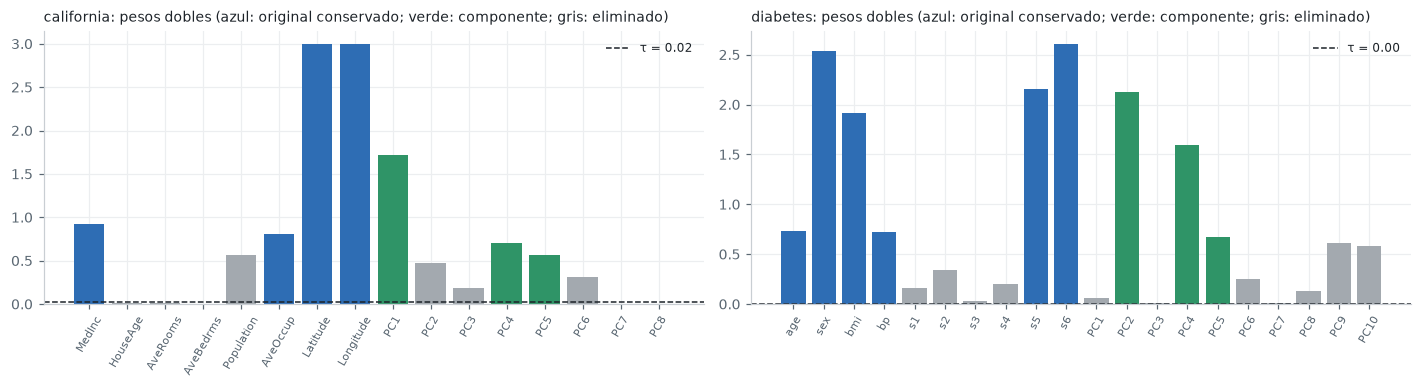

In [4]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (nombre, (P, Xt)) in zip(ejes, demo.items()):
    cols = list(pd.read_csv(os.path.join(metodo.RAIZ, metodo.PRACTICA[nombre][0])).columns.drop(metodo.PRACTICA[nombre][1]))
    etiquetas = cols + [f"PC{i+1}" for i in range(len(cols))]
    dentro = np.isin(np.arange(2 * len(cols)), P.S)
    color = np.where(dentro, np.where(np.arange(2 * len(cols)) < len(cols), A.AZUL, A.VERDE), A.GRIS)
    ax.bar(range(len(etiquetas)), P.v, color=color)
    ax.axhline(P.tau, color=A.TINTA, ls="--", lw=1, label=f"τ = {P.tau:.2f}")
    ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=60, fontsize=7)
    ax.set_title(f"{nombre}: pesos dobles (azul: original conservado; verde: componente; gris: eliminado)", loc="left", fontsize=9)
    ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. Protocolo

- **12 datasets** de regresión (los 2 de la práctica y 10 de OpenML; 6–12 atributos; ≤ 10 000 filas).
- **Diseño en dos fases.** Las variantes de v2 se compararon en un **cribado** con semillas de exploración (0–1) y 6 datasets. La elegida se **confirma** en las particiones 70/30 nuevas (semillas 40–44), las mismas de la v1, de modo que todas las comparaciones son pareadas.
- **Modelos triviales y fijos**: regresión lineal, KNN ($k=5$), árbol y Random Forest (100 árboles), por defecto.
- **Estadística por dataset** ($n=12$): media geométrica de $e'/e$ por dataset; Wilcoxon con Holm; Friedman con Nemenyi (Demšar, 2006).

## 5. Ejecución de los experimentos

In [5]:
def ejecutar(clave, carpeta, script, csv, args=(), env_extra=None, borrar=True):
    ruta_csv = os.path.join(carpeta, "resultados", csv)
    if not RECALCULAR.get(clave, False):
        estado = "guardado" if os.path.exists(ruta_csv) else "NO EXISTE: pon RECALCULAR['%s'] = True" % clave
        print(f"[{clave}] se usa el CSV {estado}: {os.path.relpath(ruta_csv, RAIZ)}")
        return
    if borrar and os.path.exists(ruta_csv):
        shutil.copy(ruta_csv, ruta_csv + ".bak"); os.remove(ruta_csv)
    env = dict(os.environ, N_JOBS=str(N_JOBS), **(env_extra or {}))
    t0 = time.time()
    print(f"[{clave}] ejecutando {script} {' '.join(args)} ...", flush=True)
    r = subprocess.run([sys.executable, script, *args], cwd=carpeta, env=env, capture_output=True, text=True)
    print(r.stdout[-800:], r.stderr[-1500:] if r.returncode else "")
    print(f"[{clave}] terminado en {(time.time()-t0)/60:.1f} min (código {r.returncode})")

ejecutar("final", FINAL, "experimento_final.py", "final.csv")
ejecutar("reduccion", REDUC, "experimento_reduccion.py", "reduccion.csv", env_extra={"VARIANTES": "τ+ρ α=0,τ α=0"}, borrar=False)
ejecutar("cribado_v2", V2, "cribado_v2.py", "cribado_v2.csv",
         env_extra={"VARIANTES": "actual,multi,multi+parada,multi+parada30,multi+selección,knn+parada"})
ejecutar("confirmacion_v2", V2, "experimento_v2.py", "confirmacion_v2.csv")
ejecutar("comparativa", FINAL, "experimento_comparativa.py", "comparativa.csv")
for bloque in ["controles", "rango", "algoritmos", "inicio"]:
    ejecutar("busqueda_" + bloque, FINAL, "experimento_busqueda.py", "busqueda.csv", args=(bloque,), borrar=False)
ejecutar("parada", FINAL, "experimento_parada.py", "parada.csv")

[final] se usa el CSV guardado: final/resultados/final.csv
[reduccion] se usa el CSV guardado: reduccion/resultados/reduccion.csv
[cribado_v2] se usa el CSV guardado: v2/resultados/cribado_v2.csv
[confirmacion_v2] se usa el CSV guardado: v2/resultados/confirmacion_v2.csv
[comparativa] se usa el CSV guardado: final/resultados/comparativa.csv
[busqueda_controles] se usa el CSV guardado: final/resultados/busqueda.csv
[busqueda_rango] se usa el CSV guardado: final/resultados/busqueda.csv
[busqueda_algoritmos] se usa el CSV guardado: final/resultados/busqueda.csv
[busqueda_inicio] se usa el CSV guardado: final/resultados/busqueda.csv
[parada] se usa el CSV guardado: final/resultados/parada.csv


## 6. Análisis completo

`analisis_v2.py` genera las figuras de `v2/figuras/` y las cifras de `v2/numeros.tex` y `v2/tablas.tex` (memoria, paper y póster de v2). También refresca `final/` (la ablación de la búsqueda es común).

In [6]:
cifras = A2.todas()
d, c = A2.cargar(), A2.cargar_comparativa()
print(len(cifras), "cifras de v2 exportadas")

135 cifras de v2 exportadas


## 7. Diseño de v2: el cribado

En semillas de **exploración** (0–1, 6 datasets), comparamos la v1 con las piezas nuevas. "Parada" aparta un 20 % de la submuestra de entrenamiento, evalúa ahí el mejor de cada generación y para si no mejora en 15 (o 30) generaciones; "elegir θ con apartado" no para, solo devuelve el mejor en esa parte apartada.

12 particiones de exploración


modelo,Regresión lineal,KNN,Árbol,Random Forest,media,evaluaciones,segundos,dim/n
representacion,,,,,,,,
actual,0.979,0.702,0.989,1.016,0.912,1000.000,102.627,0.831
multi,0.892,0.724,0.960,0.999,0.887,1002.167,171.845,0.798
multi+parada,0.897,0.734,0.989,1.018,0.902,441.250,71.366,0.754
multi+parada30,0.892,0.734,0.977,1.012,0.897,791.500,87.474,0.788
multi+selección,0.891,0.730,0.976,1.010,0.895,1002.167,98.106,0.788
knn+parada,0.963,0.725,0.978,1.011,0.911,467.833,29.753,0.777


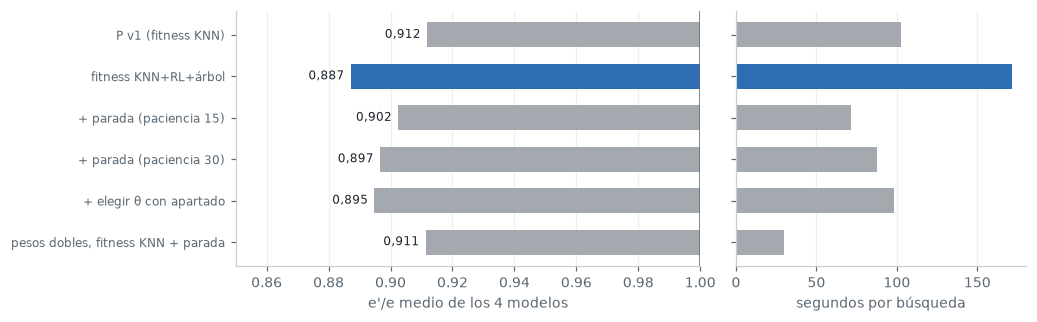

In [7]:
gc, ncr = A2.tabla_cribado()
print(ncr, "particiones de exploración")
display(gc.round(3))
A2.fig_cribado(gc); plt.show()

- **El fitness de tres modelos mejora la media** de los cuatro (0,887 frente a 0,912 de la v1): sobre todo en regresión lineal y el árbol, con algo de pérdida en KNN.
- **Parar por sobreajuste no ayuda.** Con paciencia de 15 generaciones para hacia las 440 evaluaciones (2,4 veces más rápido) pero empeora (0,902). Con más paciencia (0,897) o usando lo apartado solo para elegir el θ final, sin parar (0,895), tampoco se recupera. La pérdida no viene de cuándo se para, sino de quitar un 20 % de los datos al fitness para un criterio de 60–400 filas, demasiado ruidoso para decidir.
- **Elegida**: fitness KNN + regresión lineal + árbol, pesos dobles, sin parada.

## 8. Resultado en las particiones de confirmación

In [8]:
t = A2.tabla_principal(d)
t[["estándar", "P sin reducir", "P v1", "cociente_orig", "ds_mejora_orig", "p_holm_orig", "cambio_est", "p_holm_est"]].rename(
    columns={"P sin reducir": "P sin reducir (2n)", "cociente_orig": "P v2 (e'/e)", "ds_mejora_orig": "datasets e'<e",
             "p_holm_orig": "p Holm", "cambio_est": "% vs estándar", "p_holm_est": "p Holm vs estándar"}).round(4)

,estándar,P sin reducir (2n),P v1,P v2 (e'/e),datasets e'<e,p Holm,% vs estándar,p Holm vs estándar
modelo,,,,,,,,
Regresión lineal,0.982,0.940,0.957,0.854,11,0.027,-13.083,0.027
KNN,0.876,0.750,0.757,0.788,9,0.161,-10.012,0.386
Árbol,1.000,0.988,1.001,0.994,5,1.000,-0.662,1.000
Random Forest,1.000,0.978,1.005,1.003,5,1.000,0.293,1.000


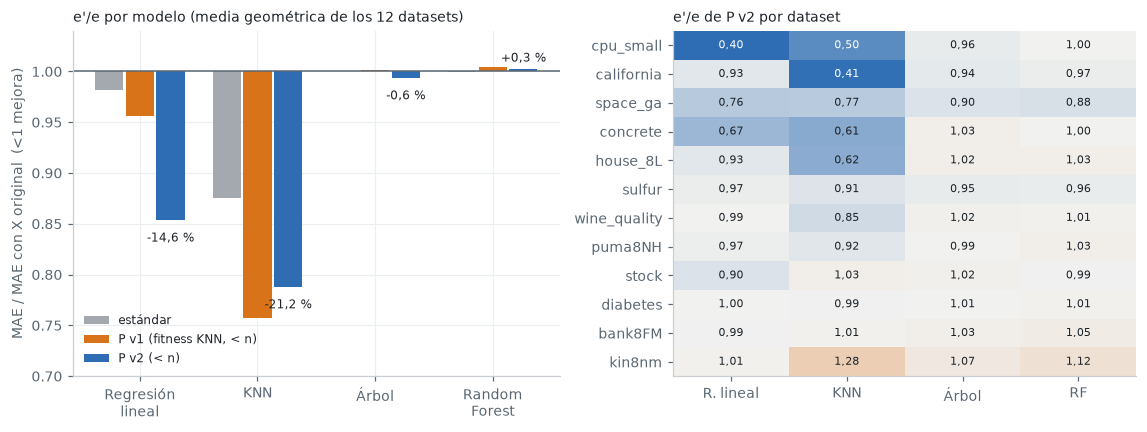

**P v2 frente a P v1** (< 1: v2 mejor)

,cociente,ds_mejora,ds,p,p_holm
modelo,,,,,
Regresión lineal,0.892,11,12,0.002,0.010
KNN,1.041,4,12,0.129,0.388
Árbol,0.992,6,12,0.677,1.000
Random Forest,0.998,8,12,0.519,1.000


**P v2 frente a P sin reducir (2n)**

,cociente,ds_mejora,ds,p,p_holm
modelo,,,,,
Regresión lineal,0.909,11,12,0.003,0.014
KNN,1.051,3,12,0.064,0.192
Árbol,1.006,5,12,0.791,0.791
Random Forest,1.026,2,12,0.129,0.259


In [9]:
A2.fig_principal(d); plt.show()
display(Markdown("**P v2 frente a P v1** (< 1: v2 mejor)"))
display(A2.efecto(d, "P v1")[["cociente", "ds_mejora", "ds", "p", "p_holm"]].round(4))
display(Markdown("**P v2 frente a P sin reducir (2n)**"))
display(A2.efecto(d, "P sin reducir")[["cociente", "ds_mejora", "ds", "p", "p_holm"]].round(4))

- **Regresión lineal**: −14,6 % (11/12 datasets, $p_{Holm}=0{,}027$), un 10,7 % mejor que la v1 ($p_{Holm}=0{,}010$). Elegir las componentes y la forma también para un modelo lineal le sirve, sobre todo en cpu_small (−60 %) y concrete (−33 %).
- **KNN**: −21,2 % (9/12), un 4 % peor que la v1 (no significativo) y ya **sin significación** tras Holm, por el caso negativo **kin8nm** (+28,5 %).
- **Árbol y Random Forest**: sin cambio en media (−0,6 % y +0,3 %). Ganan en algunos datasets (space_ga: RF −11,7 %, árbol −9,8 %; california: árbol −6 %) y pierden en otros (kin8nm, bank8FM).
- **Mayor reducción**: cpu_small con regresión lineal (−59,6 %; MAE de 6,25 a 2,52) y california con KNN (−58,7 %).

### Cuánto reduce y qué conserva

In [10]:
display(A2.tabla_dimension(d).round(2))
u = d[d.representacion == "P"].drop_duplicates(["dataset", "semilla"])
print(f"dim X'/n medio: {(u.dim/u.n_atributos).mean():.2f} · originales {u.n_orig.mean():.1f} · componentes {u.n_comp.mean():.1f}"
      f" · particiones con componentes: {(u.n_comp>0).mean():.0%} · dim X' < n en todas: {bool((u.dim < u.n_atributos).all())}")

,n,orig,comp,dim
dataset,,,,
diabetes,10,6.2,2.8,9.0
concrete_compressive_strength,8,5.8,1.0,6.8
stock,9,6.4,1.6,8.0
space_ga,6,2.8,2.2,5.0
sulfur,6,3.0,2.0,5.0
wine_quality,11,7.0,3.0,10.0
kin8nm,8,4.6,2.4,7.0
bank8FM,8,3.6,3.4,7.0
puma8NH,8,2.2,0.6,2.8


dim X'/n medio: 0.83 · originales 4.9 · componentes 2.2 · particiones con componentes: 93% · dim X' < n en todas: True


- $X'$ conserva de media **4,9 atributos originales y 2,2 componentes**, con componentes en el **93 %** de las particiones (la v1, con fitness solo de KNN, sintetizaba en el 25 %). El fitness de varios modelos **sí reparte** el presupuesto de $n-1$ atributos entre originales y direcciones oblicuas.
- En **puma8NH**, donde pocos atributos explican $y$, se queda con 3 de 8.
- En **kin8nm** el reparto falla: todos los atributos importan por igual, y cambiar originales por componentes empeora a los cuatro modelos.

## 9. Comparativa con otras transformaciones

60 particiones; p: Wilcoxon por dataset de P v2 frente a cada una, con Holm


,Regresión lineal,KNN,Árbol,Random Forest,rango medio,dim/n
P sin reducir,0.939,0.750,0.989,0.977,3.646,2.000
P,0.854,0.788,0.994,1.003,4.500,0.832
PG (gplearn),0.843,0.820,1.007,1.008,5.135,2.000
estándar + PCA,0.982,0.876,0.994,0.981,5.156,2.000
P v1,0.956,0.757,1.001,1.005,5.312,0.828
YJ máx. verosimilitud,1.024,0.855,1.015,1.017,5.583,1.000
estándar,0.982,0.876,1.000,1.000,5.948,1.000
MLKR,0.982,0.775,1.020,1.026,6.510,1.000
cuantiles,1.081,0.882,1.001,1.000,7.042,1.000
PCA v-CV,0.990,0.880,1.187,1.151,8.260,0.905


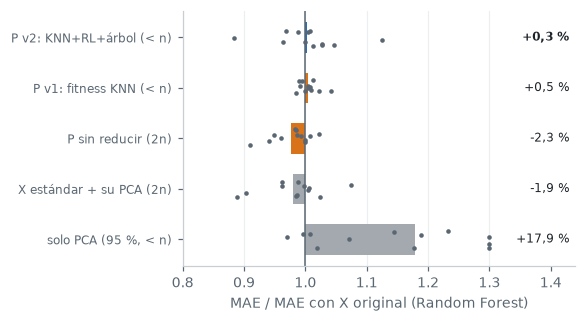

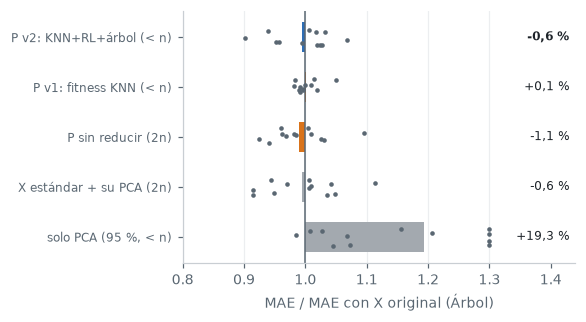

In [11]:
tc, n = A2.tabla_comparativa(c)
print(n, "particiones; p: Wilcoxon por dataset de P v2 frente a cada una, con Holm")
display(tc[A.MODELOS + ["rango medio", "dim/n"]].round(3).sort_values("rango medio"))
A2.fig_rf(c); plt.show()
A2.fig_rf(c, "Árbol"); plt.show()

- $P$ v2 es **segunda en rango medio** (4,5), solo por detrás de $P$ sin reducir (3,6), que usa $2n$ atributos, y la **mejor de las que no aumentan la dimensión**: supera a la v1 (5,3), a la programación genética (5,1, con $2n$), a añadir la PCA de $X$ estandarizado (5,2) y a MLKR (6,5).
- En **regresión lineal** es significativamente mejor que todas salvo la programación genética, con la que empata (0,85 frente a 0,84).
- **"Solo PCA"**, la otra forma de reducir, empeora a RF un 18 %: sustituir los ejes originales daña a los árboles; *elegir* cuáles conservar, no.

## 10. La búsqueda: piezas, inicio, rango y algoritmo

Estas ablaciones de la búsqueda de $(\lambda, w)$ se hicieron con $P$ sin reducir (fitness KNN). Siguen siendo válidas para la parte común de v2 (forma y pesos) y muestran que CMA-ES es robusto a su configuración.

In [12]:
b = A.cargar_busqueda()
display(A.contra_referencia(b, [v for _, v, _ in A.ABLACION if v in set(b.variante)]).round(4))
ta, n = A.tabla_algoritmos(b); print(n, "particiones comunes"); display(ta.round(3))

,casos,KNN,p KNN,ds peor KNN,Regresión lineal,p Regresión lineal,ds peor Regresión lineal,Random Forest,p Random Forest,ds peor Random Forest,p_holm KNN,p_holm Regresión lineal,p_holm Random Forest
variante,,,,,,,,,,,,,
solo pesos,24,1.022,0.424,7,1.065,0.077,9,0.999,0.622,4,1.000,0.849,1.000
solo exponentes,24,1.100,0.003,11,1.022,0.110,8,1.004,0.424,3,0.034,0.989,1.000
pesos MI,24,1.149,0.002,10,1.068,0.034,10,1.036,0.151,8,0.029,0.410,1.000
YJ máx. verosimilitud + pesos MI,24,1.110,0.007,9,1.103,0.339,7,1.036,0.064,9,0.061,1.000,0.704
búsqueda aleatoria,24,1.062,0.002,11,1.030,0.129,7,1.020,0.007,11,0.029,1.000,0.082
inicio aleatorio,24,1.006,0.850,5,1.017,0.519,7,1.006,0.970,6,1.000,1.000,1.000
sigma0=0.1,24,1.005,0.791,6,0.999,0.677,8,1.008,0.233,8,1.000,1.000,1.000
sigma0=0.4,24,1.009,0.677,6,0.996,0.733,6,1.006,0.569,6,1.000,1.000,1.000
población x2,24,1.002,0.970,6,0.998,0.970,7,1.013,0.470,7,1.000,1.000,1.000


24 particiones comunes


,rango,fitness,cambio KNN,cambio Regresión lineal
variante,,,,
CMA-ES,1.875,0.438,-25.655,-7.732
AG (propio),2.792,0.440,-24.450,-8.527
HS,3.250,0.443,-24.463,-8.323
BBO,4.417,0.445,-24.815,-7.950
PSO,4.458,0.445,-24.100,-5.126
DE,5.417,0.450,-23.330,-5.937
ABC,5.875,0.452,-23.966,-2.359
búsqueda aleatoria,7.917,0.466,-21.036,-4.919


- Los **pesos** son la pieza principal (sin ellos, KNN empeora un 10 %); la búsqueda gana a la aleatoria (+6 %) y a los pesos por información mutua (+15 %).
- CMA-ES es robusto a la población inicial y al rango de $\lambda$; con el mismo presupuesto, tiene el mejor rango de fitness, aunque otras metaheurísticas (AG, HS, BBO) quedan cerca.

### Operadores evolutivos

| | CMA-ES (método) |
|---|---|
| Individuo | $\theta=(\lambda, v, \tau)$ real en $[0,1]^{3n+1}$, reescalado a los límites |
| Población inicial | $\mathcal N(\theta_0, 0{,}2^2 I)$, $\theta_0$ = estandarizar sin componentes |
| Tamaño | $\lambda = 4+\lfloor 3\ln D\rfloor$ |
| Selección | truncamiento por rango, $\mu=\lambda/2$, pesos logarítmicos |
| Recombinación | intermedia ponderada de los $\mu$ seleccionados |
| Mutación | $\mathcal N(m,\sigma^2C)$, $\sigma$ y $C$ adaptativas |
| Reemplazo | $(\mu/\mu_w,\lambda)$ generacional; se guarda el mejor evaluado |
| Restricciones | cubo $[0,1]^D$; $\dim X'<n$ por decodificación |
| Parada | 1000 evaluaciones (la parada por sobreajuste se probó y se descartó, sección 7) |

## 11. Coste y caso negativo

In [13]:
print(f"Búsqueda de P v2: mediana {u.segundos.median():.0f} s, máximo {u.segundos.max():.0f} s por partición (20 procesos en paralelo)")
dia = d[(d.dataset == "diabetes") & (d.representacion.isin(["P v1", "P"]))].groupby(["representacion", "modelo"]).rel.apply(A.geo).unstack()
dia.round(3)

Búsqueda de P v2: mediana 292 s, máximo 438 s por partición (20 procesos en paralelo)


modelo,KNN,Random Forest,Regresión lineal,Árbol
representacion,,,,
P,0.988,1.007,0.997,1.006
P v1,0.974,1.008,1.003,0.982


Una búsqueda de v2 tarda ~5 minutos por partición con 20 procesos en paralelo (la v1, ~3 minutos): el árbol y la regresión lineal encarecen cada evaluación. Se paga una sola vez por dataset, y $X'$ tiene menos columnas que $X$. En **diabetes** (309 filas de entrenamiento) la v2 tampoco consigue trasladar la mejora del fitness a la validación.

## 12. Conclusiones

1. **$\dim X'<n$ siempre** (83 % de los atributos de media), con el criterio de eliminación aprendido por CMA-ES, y **síntesis real**: la v2 conserva componentes en el 93 % de las particiones.
2. **$e'<e$ en regresión lineal** (−14,6 %, significativo) **y KNN** (−21,2 %); en los árboles el error queda igual en media.
3. **El fitness decide para quién es la representación.** Con solo KNN, la v1 favorecía a KNN; con tres modelos, la v2 reparte mejor y gana sobre todo en regresión lineal (−9,5 % de media en los cuatro modelos, frente a −7,6 %).
4. **Es la mejor transformación de las que no aumentan la dimensión**, y segunda en rango medio entre once.
5. **La parada con datos apartados no compensa** con datasets de este tamaño.
6. **Límites**: 12 datasets pequeños; casos negativos (kin8nm, diabetes); ~5 minutos por búsqueda; a los árboles les ayuda sobre todo *añadir* dimensiones, lo que el enunciado no permite.

In [14]:
if COMPILAR_LATEX:
    subprocess.run(["pdflatex", "-interaction=nonstopmode", "esquema_v2_pdf.tex"], cwd=os.path.join(V2, "figuras"))
    for carpeta, tex in [("memoria", "memoria_v2.tex"), ("paper", "paper_v2.tex"), ("poster", "poster_v2.tex")]:
        r = subprocess.run(["latexmk", "-pdf", "-interaction=nonstopmode", tex], cwd=os.path.join(V2, carpeta),
                           capture_output=True, text=True)
        print(carpeta, "OK" if r.returncode == 0 else "ERROR")